['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'deposit']
Mean (Expected successes): 9.476796273069342
Variance: 4.986312893006293
Standard Deviation: 2.2330053499726086


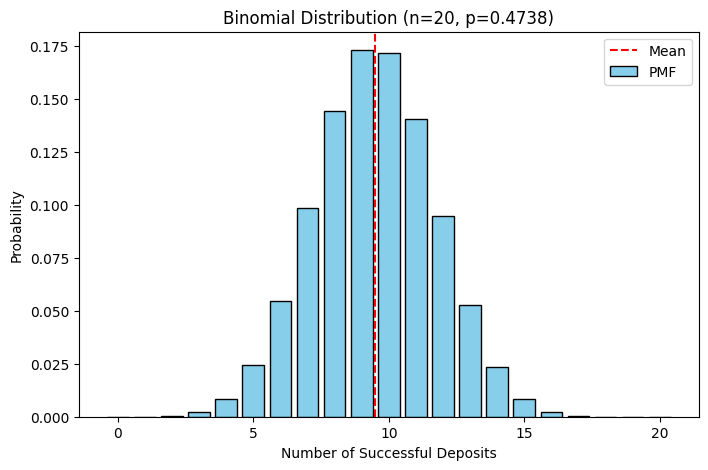

P(X >= 5): 0.9889125988954862
P(X = 8): 0.14412366981450472


In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom

df = pd.read_csv('bank.csv')

df.columns = df.columns.str.strip().str.lower()

print(df.columns.tolist())

n = 20
p = (df['deposit'].astype(str).str.strip().str.lower() == 'yes').mean()

x = np.arange(0, n + 1)

pmf = binom.pmf(x, n, p)
cdf = binom.cdf(x, n, p)

mean, var = binom.stats(n, p, moments='mv')
std_dev = np.sqrt(var)

print('Mean (Expected successes):', mean)
print('Variance:', var)
print('Standard Deviation:', std_dev)

plt.figure(figsize=(8, 5))

plt.bar(x, pmf, color='skyblue', edgecolor='black', label='PMF')
plt.axvline(mean, color='red', linestyle='--', label='Mean')
plt.title(f'Binomial Distribution (n={n}, p={p:.4f})')
plt.xlabel('Number of Successful Deposits')
plt.ylabel('Probability')
plt.legend()
plt.show()

p_at_least_5 = 1 - binom.cdf(4, n, p)
print('P(X >= 5):', p_at_least_5)

p_exactly_8 = binom.pmf(8, n, p)
print('P(X = 8):', p_exactly_8)